# What Makes Me Tired?
## A data-driven analysis of my daily habits

In this notebook I analyze my daily habits (49 days, from October 5 to November 22, 2026)
and how they relate to my tiredness (1 = not tired, 5 = very tired).

## 1. Data Loading

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu, kruskal
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [4]:
# Load the dataset (from the data/ folder, or from the same folder in Colab)
path = "data/Why_Am_I_So_Tired_final.xlsx"
if not os.path.exists(path):
    path = "Why_Am_I_So_Tired_final.xlsx"

df = pd.read_excel(path, sheet_name="Daily data")

# Folders to save figures and results
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

df.head()

,date,university_day,class_hours,study_hours,bedtime,wake_up_time,sleep_hours,nap_duration_min,screen_time_hours,screen_before_bed_min,gym_duration_min,steps,tiredness,notes
0,2026-10-05,No,4,2,23:00,07:45,8.75,15,7.61667,20,90,5579,2,classes online per la pluja
1,2026-10-06,Yes,4,3,23:30,06:15,6.75,60,3.15000,20,60,7700,3,NaN
2,2026-10-07,Yes,6,3,23:15,06:15,7.00,0,5.46667,40,0,7566,3,NaN
3,2026-10-08,Yes,4,2,23:30,06:30,7.00,0,5.15000,0,0,11423,3,NaN
4,2026-10-09,Yes,4,5,23:00,06:00,7.00,60,4.41667,0,90,9339,3,NaN


## 2. Data Preprocessing

Sleep variables refer to the night before each day. No days are removed.

In [5]:
# Check missing values and duplicated dates
print(df.isnull().sum())
print("Duplicated dates:", df['date'].duplicated().sum())

date                      0
university_day            0
class_hours               0
study_hours               0
bedtime                   0
wake_up_time              0
sleep_hours               0
nap_duration_min          0
screen_time_hours         0
screen_before_bed_min     0
gym_duration_min          0
steps                     0
tiredness                 0
notes                    38
dtype: int64
Duplicated dates: 0


In [6]:
# Convert types
df['date'] = pd.to_datetime(df['date'])
df['university_day'] = df['university_day'].map({'No': 0, 'Yes': 1})

df.describe().round(2)

,date,university_day,class_hours,study_hours,sleep_hours,nap_duration_min,screen_time_hours,screen_before_bed_min,gym_duration_min,steps,tiredness
count,49,49.00,49.00,49.00,49.00,49.00,49.00,49.00,49.00,49.00,49.00
mean,2026-10-29 00:00:00,0.61,2.73,3.12,7.42,30.51,3.77,17.65,33.06,6969.39,2.71
min,2026-10-05 00:00:00,0.00,0.00,0.00,3.50,0.00,2.25,0.00,0.00,1677.00,1.00
25%,2026-10-17 00:00:00,0.00,0.00,2.00,6.75,0.00,3.12,0.00,0.00,5194.00,2.00
50%,2026-10-29 00:00:00,1.00,4.00,3.00,7.33,0.00,3.57,0.00,0.00,7566.00,3.00
75%,2026-11-10 00:00:00,1.00,6.00,4.00,8.00,30.00,4.20,30.00,90.00,8929.00,3.00
max,2026-11-22 00:00:00,1.00,6.00,8.00,10.50,180.00,7.62,90.00,90.00,12287.00,5.00
std,NaN,0.49,2.60,1.94,1.26,47.52,1.00,24.62,42.42,2720.54,0.96


## 3. Feature Engineering

New variables: total academic hours, total sleep (night + nap), weekend, and the type of day
(party, sick or normal) from my notes.

In [7]:
df['total_academic_hours'] = df['class_hours'] + df['study_hours']
df['total_sleep_hours'] = df['sleep_hours'] + df['nap_duration_min'] / 60
df['weekend'] = (df['date'].dt.dayofweek >= 5).astype(int)

# Type of day from my notes
notes = df['notes'].fillna('')
df['day_type'] = 'normal'
df.loc[notes.str.contains('festa|discoteca|tardeo'), 'day_type'] = 'party'
df.loc[notes.str.contains('malalta'), 'day_type'] = 'sick'

print(df['day_type'].value_counts())
print("Gym days:", (df['gym_duration_min'] > 0).sum())

day_type
normal    40
party      6
sick       3
Name: count, dtype: int64
Gym days: 19


## 4. Exploratory Data Analysis

In [8]:
# How many days for each tiredness level
print(df['tiredness'].value_counts().sort_index())
print("Mean tiredness:", round(df['tiredness'].mean(), 2))

# Mean tiredness by type of day
print(df.groupby('day_type')['tiredness'].mean().round(2))

tiredness
1     4
2    18
3    16
4    10
5     1
Name: count, dtype: int64
Mean tiredness: 2.71
day_type
normal    2.55
party     3.33
sick      3.67
Name: tiredness, dtype: float64


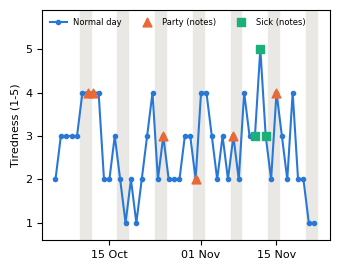

In [9]:
# Figure 1: tiredness over time
fig, ax = plt.subplots(figsize=(3.5, 2.8))

# Grey background on weekends
for d in df.loc[df['weekend'] == 1, 'date']:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color='#e9e8e4')

ax.plot(df['date'], df['tiredness'], marker='o', markersize=3, color='#2a78d6', label='Normal day')

party = df[df['day_type'] == 'party']
sick = df[df['day_type'] == 'sick']
ax.scatter(party['date'], party['tiredness'], marker='^', s=40, color='#eb6834', zorder=3, label='Party (notes)')
ax.scatter(sick['date'], sick['tiredness'], marker='s', s=35, color='#1baf7a', zorder=3, label='Sick (notes)')

ax.set_ylabel('Tiredness (1-5)', fontsize=8)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_ylim(0.6, 5.9)
ax.set_xticks(pd.to_datetime(['2026-10-15', '2026-11-01', '2026-11-15']))
ax.set_xticklabels(['15 Oct', '01 Nov', '15 Nov'])
ax.tick_params(labelsize=8)
ax.legend(loc='upper left', ncol=3, fontsize=6, frameon=False)
plt.tight_layout()
plt.savefig('figures/fig1_tiredness_timeline.png', dpi=300)
plt.show()

In [10]:
# University days vs. other days
print(df.groupby('university_day')['tiredness'].mean().round(2))

uni = df[df['university_day'] == 1]['tiredness']
no_uni = df[df['university_day'] == 0]['tiredness']
print("Mann-Whitney p-value:", round(mannwhitneyu(uni, no_uni).pvalue, 3))

university_day
0    2.47
1    2.87
Name: tiredness, dtype: float64
Mann-Whitney p-value: 0.189


## 5. Correlation Analysis

Spearman correlation is used because tiredness is an ordinal scale.
A p-value below 0.05 means the correlation is significant.
I also repeat the analysis without the exceptional days (party and sick days).

In [11]:
habits = ['sleep_hours', 'total_sleep_hours', 'steps', 'screen_time_hours', 'study_hours',
          'university_day', 'total_academic_hours', 'gym_duration_min']

normal_days = df[df['day_type'] == 'normal']

rows = []
for h in habits:
    rho_all, p_all = spearmanr(df[h], df['tiredness'])
    rho_normal, p_normal = spearmanr(normal_days[h], normal_days['tiredness'])
    rows.append([h, rho_all, p_all, rho_normal, p_normal])

correlations = pd.DataFrame(rows, columns=['habit', 'rho_all_days', 'p_all_days',
                                           'rho_without_exceptional', 'p_without_exceptional'])
correlations.round(3)

,habit,rho_all_days,p_all_days,rho_without_exceptional,p_without_exceptional
0,sleep_hours,-0.301,0.036,-0.476,0.002
1,total_sleep_hours,-0.224,0.121,-0.349,0.027
2,steps,0.323,0.024,0.417,0.007
3,screen_time_hours,0.311,0.030,0.278,0.083
4,study_hours,-0.269,0.062,-0.164,0.312
5,university_day,0.191,0.188,0.377,0.016
6,total_academic_hours,-0.061,0.677,0.219,0.175
7,gym_duration_min,-0.033,0.823,0.115,0.481


## 6. Sleep Over Several Days

Is my tiredness related to the sleep of the last few nights, and not only the last one?
I compare the previous night with the average of the last 3 nights (using the same 47 days),
and then try averages from 1 to 7 nights.

In [12]:
df['sleep_3days'] = df['sleep_hours'].rolling(3).mean()
days = df.dropna(subset=['sleep_3days'])  # the first 2 days have no 3-day average

rho, p = spearmanr(days['sleep_hours'], days['tiredness'])
print(f"Previous night: rho = {rho:.3f}, p = {p:.3f}")
rho, p = spearmanr(days['sleep_3days'], days['tiredness'])
print(f"Last 3 nights:  rho = {rho:.3f}, p = {p:.3f}")

Previous night: rho = -0.285, p = 0.052
Last 3 nights:  rho = -0.431, p = 0.003


In [13]:
# Correlation for averages from 1 to 7 nights
windows = [1, 2, 3, 4, 5, 6, 7]
rho_all = []
rho_normal = []

for w in windows:
    df['sleep_avg'] = df['sleep_hours'].rolling(w).mean()
    data = df.dropna(subset=['sleep_avg'])
    rho_all.append(spearmanr(data['sleep_avg'], data['tiredness'])[0])
    data = data[data['day_type'] == 'normal']
    rho_normal.append(spearmanr(data['sleep_avg'], data['tiredness'])[0])

sleep_windows = pd.DataFrame({'nights': windows, 'rho_all_days': rho_all,
                              'rho_without_exceptional': rho_normal})
print(sleep_windows.round(3))

   nights  rho_all_days  rho_without_exceptional
0       1        -0.301                   -0.476
1       2        -0.323                   -0.460
2       3        -0.431                   -0.614
3       4        -0.278                   -0.514
4       5        -0.180                   -0.436
5       6        -0.142                   -0.319
6       7        -0.087                   -0.226


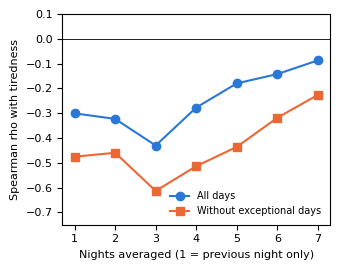

In [14]:
# Figure 2
fig, ax = plt.subplots(figsize=(3.5, 2.8))
ax.plot(windows, rho_all, marker='o', color='#2a78d6', label='All days')
ax.plot(windows, rho_normal, marker='s', color='#eb6834', label='Without exceptional days')
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xlabel('Nights averaged (1 = previous night only)', fontsize=8)
ax.set_ylabel('Spearman rho with tiredness', fontsize=8)
ax.set_ylim(-0.75, 0.1)
ax.tick_params(labelsize=8)
ax.legend(fontsize=7, frameon=False, loc='lower right')
plt.tight_layout()
plt.savefig('figures/fig2_sleep_window.png', dpi=300)
plt.show()

## 7. Clustering

K-means groups days with similar habits. Tiredness is not used to make the groups.
The variables are standardized first because they have different units.

k=2: silhouette = 0.216
k=3: silhouette = 0.237
k=4: silhouette = 0.214
k=5: silhouette = 0.223
k=6: silhouette = 0.245


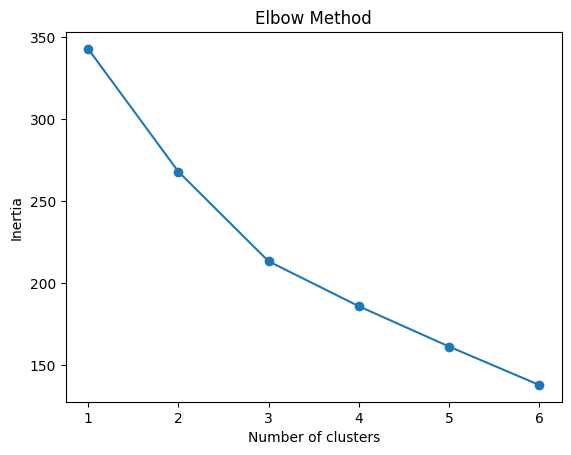

In [15]:
features = ['sleep_hours', 'nap_duration_min', 'total_academic_hours', 'screen_time_hours',
            'screen_before_bed_min', 'gym_duration_min', 'steps']
X = StandardScaler().fit_transform(df[features])

# Choose the number of clusters
inertias = []
for k in range(1, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertias.append(model.inertia_)
    if k >= 2:
        print(f"k={k}: silhouette = {silhouette_score(X, model.labels_):.3f}")

plt.plot(range(1, 7), inertias, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [16]:
# K-means with 3 clusters
df['cluster'] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X)

# Average habits and tiredness of each cluster
cluster_profiles = df.groupby('cluster')[features + ['tiredness']].mean()
cluster_profiles['days'] = df['cluster'].value_counts().sort_index()
cluster_profiles.round(2).T

cluster,0,1,2
sleep_hours,6.28,8.69,7.27
nap_duration_min,105.00,5.00,14.26
total_academic_hours,2.60,4.17,7.81
screen_time_hours,3.90,3.48,3.85
screen_before_bed_min,1.00,3.33,30.19
gym_duration_min,9.00,15.00,50.00
steps,7692.30,3910.17,8061.30
tiredness,3.10,2.42,2.70
days,10.00,12.00,27.00


In [17]:
# Which days are in each cluster?
print(pd.crosstab(df['cluster'], df['weekend']))
print(pd.crosstab(df['cluster'], df['day_type']))

# Is tiredness different between clusters?
groups = [df[df['cluster'] == c]['tiredness'] for c in range(3)]
print("Kruskal-Wallis p-value:", round(kruskal(*groups).pvalue, 3))

weekend   0  1
cluster       
0         1  9
1         7  5
2        27  0
day_type  normal  party  sick
cluster                      
0              5      5     0
1              9      1     2
2             26      0     1
Kruskal-Wallis p-value: 0.177


## 8. Export Results

In [18]:
df.drop(columns='sleep_avg').to_csv('results/tiredness_processed.csv', index=False)
correlations.to_csv('results/correlations.csv', index=False)
sleep_windows.to_csv('results/sleep_windows.csv', index=False)
cluster_profiles.to_csv('results/cluster_profiles.csv')